In [1]:
import numpy as np
import pandas as pd 
import seaborn as sns   
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_excel(r"C:\Users\vimal_z0\Downloads\ML Files\Data Sets\housing_price_dataset.xlsx")
df

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,Rural,1969,215355.283618
1,2459,3,2,Rural,1980,195014.221626
2,1860,2,1,Suburb,1970,306891.012076
3,2294,2,1,Urban,1996,206786.787153
4,2130,5,2,Suburb,2001,272436.239065
...,...,...,...,...,...,...
49995,1282,5,3,Rural,1975,100080.865895
49996,2854,2,2,Suburb,1988,374507.656727
49997,2979,5,3,Suburb,1962,384110.555590
49998,2596,5,2,Rural,1984,380512.685957


In [3]:
df.isnull().sum()

SquareFeet      0
Bedrooms        0
Bathrooms       0
Neighborhood    0
YearBuilt       0
Price           0
dtype: int64

In [4]:
df.dtypes

SquareFeet        int64
Bedrooms          int64
Bathrooms         int64
Neighborhood        str
YearBuilt         int64
Price           float64
dtype: object

In [5]:
df.nunique()

SquareFeet       2000
Bedrooms            4
Bathrooms           3
Neighborhood        3
YearBuilt          72
Price           50000
dtype: int64

In [6]:
from sklearn.preprocessing import LabelEncoder
le =LabelEncoder()

In [7]:
df["Neighborhood"] = le.fit_transform(df["Neighborhood"])
df

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,0,1969,215355.283618
1,2459,3,2,0,1980,195014.221626
2,1860,2,1,1,1970,306891.012076
3,2294,2,1,2,1996,206786.787153
4,2130,5,2,1,2001,272436.239065
...,...,...,...,...,...,...
49995,1282,5,3,0,1975,100080.865895
49996,2854,2,2,1,1988,374507.656727
49997,2979,5,3,1,1962,384110.555590
49998,2596,5,2,0,1984,380512.685957


In [8]:
df.describe()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,2006.374680,3.498700,1.995420,0.998540,1985.404420,224827.325151
std,575.513241,1.116326,0.815851,0.815838,20.719377,76141.842966
min,1000.000000,2.000000,1.000000,0.000000,1950.000000,-36588.165397
25%,1513.000000,3.000000,1.000000,0.000000,1967.000000,169955.860225
50%,2007.000000,3.000000,2.000000,1.000000,1985.000000,225052.141166
75%,2506.000000,4.000000,3.000000,2.000000,2003.000000,279373.630052
max,2999.000000,5.000000,3.000000,2.000000,2021.000000,492195.259972


In [9]:
X = df.drop(["Price"], axis =1)
X

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
0,2126,4,1,0,1969
1,2459,3,2,0,1980
2,1860,2,1,1,1970
3,2294,2,1,2,1996
4,2130,5,2,1,2001
...,...,...,...,...,...
49995,1282,5,3,0,1975
49996,2854,2,2,1,1988
49997,2979,5,3,1,1962
49998,2596,5,2,0,1984


In [10]:
Y = df["Price"]
Y

0        215355.283618
1        195014.221626
2        306891.012076
3        206786.787153
4        272436.239065
             ...      
49995    100080.865895
49996    374507.656727
49997    384110.555590
49998    380512.685957
49999    221618.583218
Name: Price, Length: 50000, dtype: float64

In [13]:
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler(feature_range =(0,1))
X1 = minmax.fit_transform(X)
X1 = pd.DataFrame(X1, columns =X.columns)
X1.describe()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.503439,0.499567,0.497710,0.499270,0.498654
std,0.287901,0.372109,0.407925,0.407919,0.291822
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.256628,0.333333,0.000000,0.000000,0.239437
50%,0.503752,0.333333,0.500000,0.500000,0.492958
75%,0.753377,0.666667,1.000000,1.000000,0.746479
max,1.000000,1.000000,1.000000,1.000000,1.000000


In [14]:
X1 = pd.concat([X1,Y], axis =1)
X1

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,0.563282,0.666667,0.0,0.0,0.267606,215355.283618
1,0.729865,0.333333,0.5,0.0,0.422535,195014.221626
2,0.430215,0.000000,0.0,0.5,0.281690,306891.012076
3,0.647324,0.000000,0.0,1.0,0.647887,206786.787153
4,0.565283,1.000000,0.5,0.5,0.718310,272436.239065
...,...,...,...,...,...,...
49995,0.141071,1.000000,1.0,0.0,0.352113,100080.865895
49996,0.927464,0.000000,0.5,0.5,0.535211,374507.656727
49997,0.989995,1.000000,1.0,0.5,0.169014,384110.555590
49998,0.798399,1.000000,0.5,0.0,0.478873,380512.685957


In [17]:
X1.to_csv("HousePricing_Cleaned.csv", index =False)

In [18]:
df1 = pd.read_csv("HousePricing_Cleaned.csv")
df1

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,0.563282,0.666667,0.0,0.0,0.267606,215355.283618
1,0.729865,0.333333,0.5,0.0,0.422535,195014.221626
2,0.430215,0.000000,0.0,0.5,0.281690,306891.012076
3,0.647324,0.000000,0.0,1.0,0.647887,206786.787153
4,0.565283,1.000000,0.5,0.5,0.718310,272436.239065
...,...,...,...,...,...,...
49995,0.141071,1.000000,1.0,0.0,0.352113,100080.865895
49996,0.927464,0.000000,0.5,0.5,0.535211,374507.656727
49997,0.989995,1.000000,1.0,0.5,0.169014,384110.555590
49998,0.798399,1.000000,0.5,0.0,0.478873,380512.685957


In [20]:
x = df1.drop("Price", axis =1)
x

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
0,0.563282,0.666667,0.0,0.0,0.267606
1,0.729865,0.333333,0.5,0.0,0.422535
2,0.430215,0.000000,0.0,0.5,0.281690
3,0.647324,0.000000,0.0,1.0,0.647887
4,0.565283,1.000000,0.5,0.5,0.718310
...,...,...,...,...,...
49995,0.141071,1.000000,1.0,0.0,0.352113
49996,0.927464,0.000000,0.5,0.5,0.535211
49997,0.989995,1.000000,1.0,0.5,0.169014
49998,0.798399,1.000000,0.5,0.0,0.478873


In [21]:
y = df1["Price"]
y

0        215355.283618
1        195014.221626
2        306891.012076
3        206786.787153
4        272436.239065
             ...      
49995    100080.865895
49996    374507.656727
49997    384110.555590
49998    380512.685957
49999    221618.583218
Name: Price, Length: 50000, dtype: float64

In [22]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.25, random_state=42)

In [24]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score

metric_k =[]
neighbors = np.arange(1,15)
for k in neighbors:
    knn = KNeighborsRegressor(n_neighbors =k)
    model = knn.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    r2 = r2_score(y_pred, y_test)
    metric_k.append(r2)
metric_k

[0.12230952332709355,
 0.16351053970563378,
 0.1830607764145329,
 0.19460999220088282,
 0.20212591536687596,
 0.20924022753688998,
 0.2133627449198593,
 0.21842475404385853,
 0.21689173167471887,
 0.218874375623477,
 0.21675913153749948,
 0.21726677744102085,
 0.21796118451388724,
 0.21741239643762744]

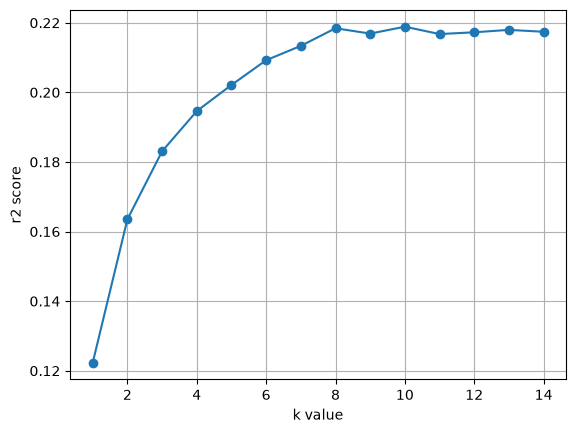

In [25]:
plt.plot(neighbors, metric_k, "o-")
plt.xlabel("k value")
plt.ylabel("r2 score")
plt.grid()
plt.show()

In [30]:
from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor(n_neighbors= 10)
model = knn.fit(x_train, y_train)
y_pred = model.predict(x_test)

In [31]:
from sklearn.metrics import mean_squared_error, r2_score
print("MSE:", mean_squared_error(y_pred,y_test))
print("r2 score:", r2_score(y_test, y_pred))

MSE: 2715908774.011357
r2 score: 0.5291281057184857


In [32]:
x_train.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
27434,0.592296,0.000000,0.0,0.0,0.211268
13400,0.718859,0.333333,0.5,1.0,0.295775
883,0.083042,0.333333,1.0,0.5,0.746479
7303,0.516758,1.000000,1.0,0.0,0.028169
45124,0.715858,0.666667,1.0,0.5,0.802817


In [33]:
y_train.head()

27434    356225.628098
13400    285884.910135
883      206852.129632
7303     234912.368919
45124    178061.311989
Name: Price, dtype: float64

In [34]:
model.predict([[0.592296,	0.000000,	0.0,	0.0,	0.211268]])

c:\Users\vimal_z0\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(


array([217107.03994865])